In [1]:
import numpy as np 
import scipy as sp
import matplotlib.pyplot as plt
from scipy.stats import t
import pandas as pd

In [2]:
def Ti_model(r, T0, Toff, gamma, a = 18e-2):
    base = np.maximum(0.0,1-(r/a)**2)
    power = gamma
    return (T0-Toff)* (base**power) + Toff

def residual(params, r, y, yerr):
    T0,Toff,gamma = params
    y_model = Ti_model(r,T0,Toff,gamma)
    return (y - y_model)/yerr

# ========== Dados Experimentais ==========
r_data = np.array([0.1021, 4.5631, 6.6125, 10, 12, 14, 16, 17]) / 100.0  # [m]
Ti_reconstructed = np.array([269.93, 212.63, 154.58, 94.59, 72.86, 58.17, 30.54, 32.0])  # [eV]
Ti_data_err = 1.0 * np.array([12.54, 8.89, 9.70, 16.0, 15.0, 13.0, 10.0, 11.0])  # Incertezas [eV]

Tmax = 270
gamma = 3.5
Toff = 30


### Dicionário de ajuste com as métricas importantes
dic_ajust = {
    'T0': [],
    'T0Err':[],
    'Toff': [],
    'ToffErr': [],
    'gamma': [],
    'gammaErr':[],
    'RMSE': [],
    'X^2': [],
    'X_red^2': [],
    'R^2': [],
    'BIC': [],
    'AIC': [],

}

## Aplicação do método par diferentes valores iniciais

t0 = np.asarray([Tmax,Toff,gamma])
ajuste = sp.optimize.least_squares(residual, x0 = t0, method = 'trf', args=(r_data,Ti_reconstructed, Ti_data_err))

## Cálculo das métricas

_chi2 = np.sum(ajuste.fun**2)
SStotal = np.sum((Ti_reconstructed - np.mean(Ti_reconstructed))**2)
dof = len(Ti_reconstructed) - len(ajuste.x)        
_chi2_red = _chi2/dof
_r2 = 1 - _chi2/SStotal
n = len(r_data)
_AIC = n*np.log(_chi2/n) + 2*len(ajuste.x)
_BIC = n*np.log(_chi2/n) + len(ajuste.x)*np.log(n)
_RMSE = np.sqrt(_chi2/n)

## Cálculo do ajuste

_T0 = ajuste.x[0]
_Toff = ajuste.x[1]
_gamma = ajuste.x[2]

J = ajuste.jac
cov = np.linalg.inv(J.T @ J)
error = np.sqrt(np.diag(cov))
var_pred = J @ cov @ J.T

_T0Err = error[0]
_ToffErr = error[1]
_gammaErr = error[2]



## Salvando no dicionário

dic_ajust['T0'].append(_T0)
dic_ajust['T0Err'].append(_T0Err)
dic_ajust['Toff'].append(_Toff)
dic_ajust['ToffErr'].append(_ToffErr)
dic_ajust['gamma'].append(_gamma)
dic_ajust['gammaErr'].append(_gammaErr)
dic_ajust['X^2'].append(_chi2)
dic_ajust['RMSE'].append(float(_RMSE))
dic_ajust['X_red^2'].append(float(_chi2_red))
dic_ajust['R^2'].append(float(_r2))
dic_ajust['BIC'].append(float(_BIC))
dic_ajust['AIC'].append(float(_AIC))

df_result = pd.DataFrame(dic_ajust)

In [3]:
#### Intervalo de confiança

#### Definindo malha fina
_r = np.linspace(0, 0.18, 1000)
_ybest = Ti_model(_r,_T0,_Toff,_gamma)
alpha_bicaudal = 1 - (1 - .95) / 2

### Calculo na malha fina
pred_var = np.zeros_like(_r)

for i in range(len(_r)):
    X = 1.0 - (_r[i] / 0.18) ** 2
    if X <= 0.0:
        dTmax = 0.0
        dTmin = 1.0
        dn = 0.0
    else:
        dTmax = X ** _gamma
        dTmin = 1.0 - (X ** _gamma)
        dn = (_T0 - _Toff) * (X ** _gamma) * np.log(X)
        
    J_val = np.array([dTmax, dTmin, dn])
    pred_var[i] = J_val @ cov @ J_val.T

conf_range = t.ppf(alpha_bicaudal, df = len(Ti_reconstructed)-1) * np.sqrt(pred_var + (_RMSE ** 2) + (np.std(Ti_data_err) ** 2))

y_upper = _ybest + conf_range
y_lower = _ybest - conf_range


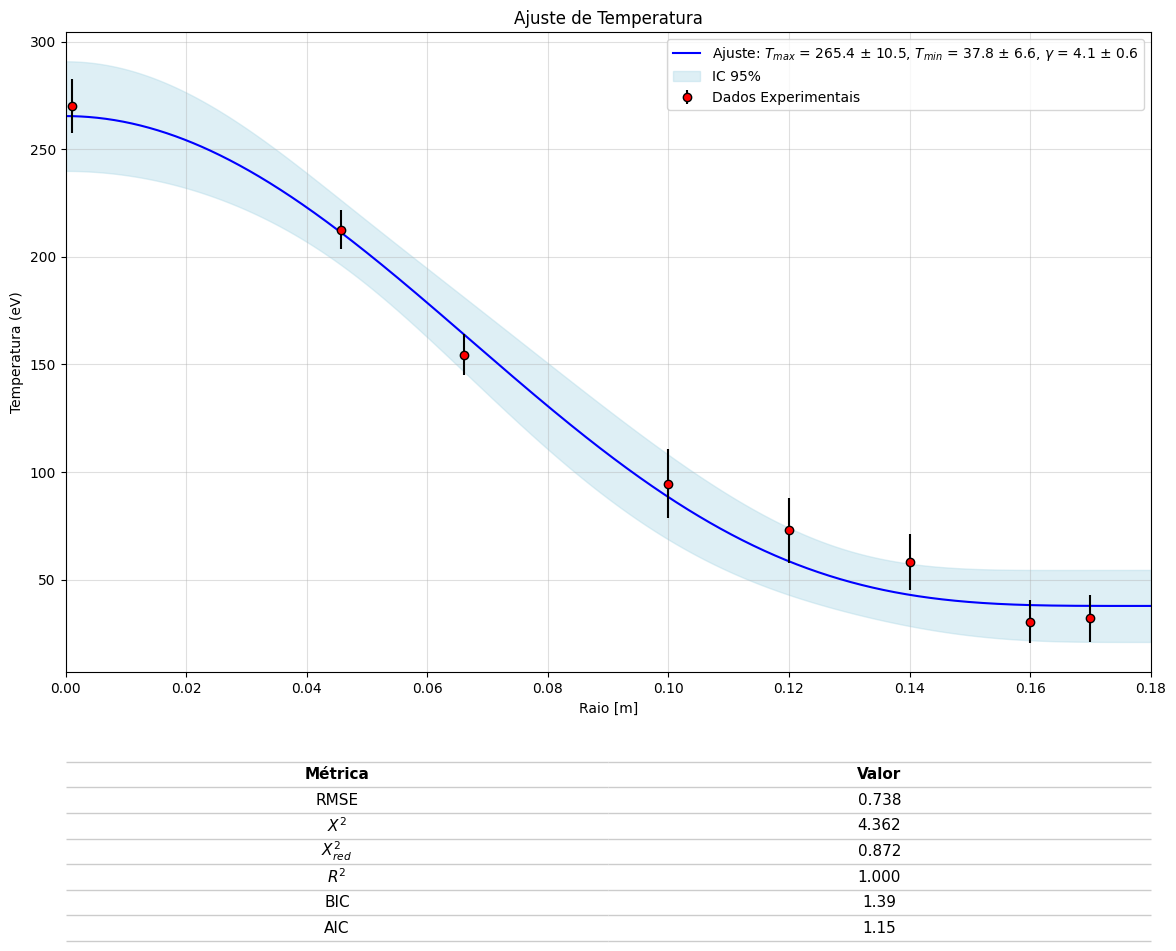

In [4]:
### Ajuste de temperaturas
fig, ax = plt.subplots(figsize=(14, 8))

# 1. Curva ajustada com os parâmetros e erros na legenda
ax.plot(_r, 
        _ybest, 
        label=f'Ajuste: $T_{{max}}$ = {_T0:.1f} $\pm$ {_T0Err:.1f}, $T_{{min}}$ = {_Toff:.1f} $\pm$ {_ToffErr:.1f}, $\gamma$ = {_gamma:.1f} $\pm$ {_gammaErr:.1f}',
        c = 'blue',
        ls = '-'
       )

# 2. Dados experimentais com barras de erro tracejadas
eb = ax.errorbar(
    r_data, Ti_reconstructed, Ti_data_err, 
    fmt='o', c='black', mec='black', mfc='red', 
    label='Dados Experimentais'
)

ax.set_xlabel('Raio [m]')
ax.set_ylabel('Temperatura (eV)')

# 3. Banda de confiança, título e grade utilizando o ax
ax.fill_between(_r, y_lower, y_upper, color='lightblue', alpha=0.4, label='IC 95%')
ax.set_title("Ajuste de Temperatura")
ax.set_xlim(0,.18)
ax.grid(True, which='both', alpha=0.4)
ax.legend(loc='upper right')

# 4. Dados da tabela de métricas
table_data = [
    ['RMSE', f"{_RMSE:.3f}"],
    ['$X^2$', f"{_chi2:.3f}"],
    ['$X_{red}^2$', f"{_chi2_red:.3f}"],
    ['$R^2$', f"{_r2:.3f}"],
    ['BIC', f"{_BIC:.2f}"],
    ['AIC', f"{_AIC:.2f}"]
]

col_labels = ['Métrica', 'Valor']

# Adiciona a tabela ao eixo principal
table = ax.table(
    cellText=table_data,
    colLabels=col_labels,
    loc='bottom',
    cellLoc='center',
    bbox=[0.0, -0.42, 1.0, 0.28]
)

# Estilização refinada da tabela (sem linhas verticais e cabeçalho destacado)
table.set_fontsize(11)
table.scale(1, 1.3)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#cccccc') # Cor de borda cinza claro
    if row == 0:
        cell.set_facecolor('#f0f0f0')
        cell.set_text_props(weight='bold', color='black')
        cell.visible_edges = 'TB'  
    else:
        cell.visible_edges = 'B'

# Ajusta o espaçamento inferior da janela para a tabela não ser cortada
plt.subplots_adjust(bottom=0.08)

plt.savefig('../../Resultados/17112026/Ajuste_temp.png')
plt.show()

In [5]:
### Ajuste das velocidades

### Modelagem modelo a priori
